# Task 1 — Credit Scoring Model
*CodeAlpha Machine Learning Internship*

**Goal:** predict whether a loan applicant is **creditworthy** (`1`) or **not creditworthy** (`0`) from their financial profile.

**Dataset:** 5,000 synthetic applicants generated by [`generate_data.py`](generate_data.py) with five features: `Income`, `Debts`, `Payment_History`, `Loan_Amount`, `Age`.

> ⚠️ **Important limitation:** the label was produced by a hand-written formula:
> `score = Income/1000 − Debts/2000 + 20·Payment_History − Loan_Amount/5000 + Age/10`, and `Creditworthy = score > 50`.
> The label is therefore a deterministic function of the features with no noise. High scores here show that the
> pipeline works, **not** that the model would work on real credit data.

**Which metric matters?** For a lender, approving an applicant who later defaults usually costs more than rejecting a good one.
So besides accuracy we track:
- **ROC-AUC** — how well the model *ranks* applicants by risk, independent of any threshold.
- **Recall on class 0 (not creditworthy)** — the share of risky applicants that we actually catch.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, roc_auc_score, make_scorer, recall_score)

RANDOM_STATE = 42
CLASS_NAMES = ["Not creditworthy", "Creditworthy"]
sns.set_theme(style="whitegrid")

## 1. Load and inspect the data

In [2]:
df = pd.read_csv("data/credit_data.csv")
print("Shape:", df.shape)
df.head()

Shape: (5000, 6)


,Income,Debts,Payment_History,Loan_Amount,Age,Creditworthy
0,141958,51919,1,20419,48,1
1,35795,27103,0,40017,42,0
2,20860,36188,0,40577,64,0
3,123694,5845,0,7921,50,1
4,148106,36674,0,9676,52,1


In [3]:
print("Missing values per column:\n", df.isna().sum(), sep="")
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().T

Missing values per column:
Income             0
Debts              0
Payment_History    0
Loan_Amount        0
Age                0
Creditworthy       0
dtype: int64

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Income,5000.0,84563.1930,37886.080677,20055.0,51333.75,84338.5,117152.75,149992.0
Debts,5000.0,39385.9644,23155.474592,28.0,19597.00,38760.5,59235.00,79980.0
Payment_History,5000.0,0.4900,0.499950,0.0,0.00,0.0,1.00,1.0
Loan_Amount,5000.0,27168.7448,12787.884114,5005.0,15959.00,27016.0,38103.75,49989.0
Age,5000.0,40.7832,13.620620,18.0,29.00,41.0,53.00,64.0
Creditworthy,5000.0,0.6724,0.469385,0.0,0.00,1.0,1.00,1.0


## 2. Exploratory data analysis

### 2.1 Class balance
If the classes are imbalanced, a model that always predicts the majority class already gets a high accuracy. That accuracy is the baseline any real model has to beat.

                  count  share
Not creditworthy   1638  0.328
Creditworthy       3362  0.672


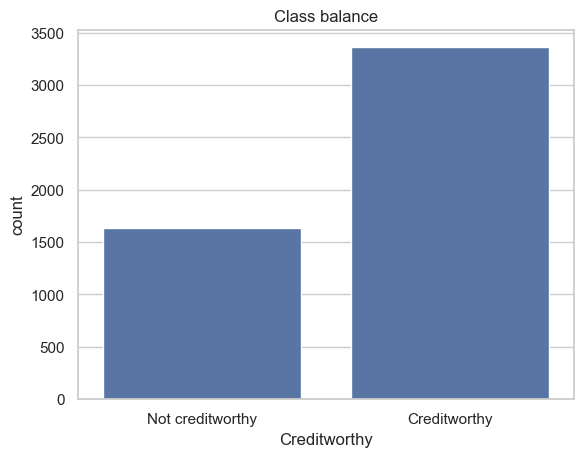

In [4]:
counts = df["Creditworthy"].value_counts().sort_index()
print(pd.DataFrame({"count": counts, "share": (counts / len(df)).round(3)}, index=[0, 1]).rename(index=dict(enumerate(CLASS_NAMES))))

ax = sns.countplot(x="Creditworthy", data=df)
ax.set_xticks([0, 1], CLASS_NAMES)
ax.set_title("Class balance")
plt.show()

### 2.2 Feature distributions by class

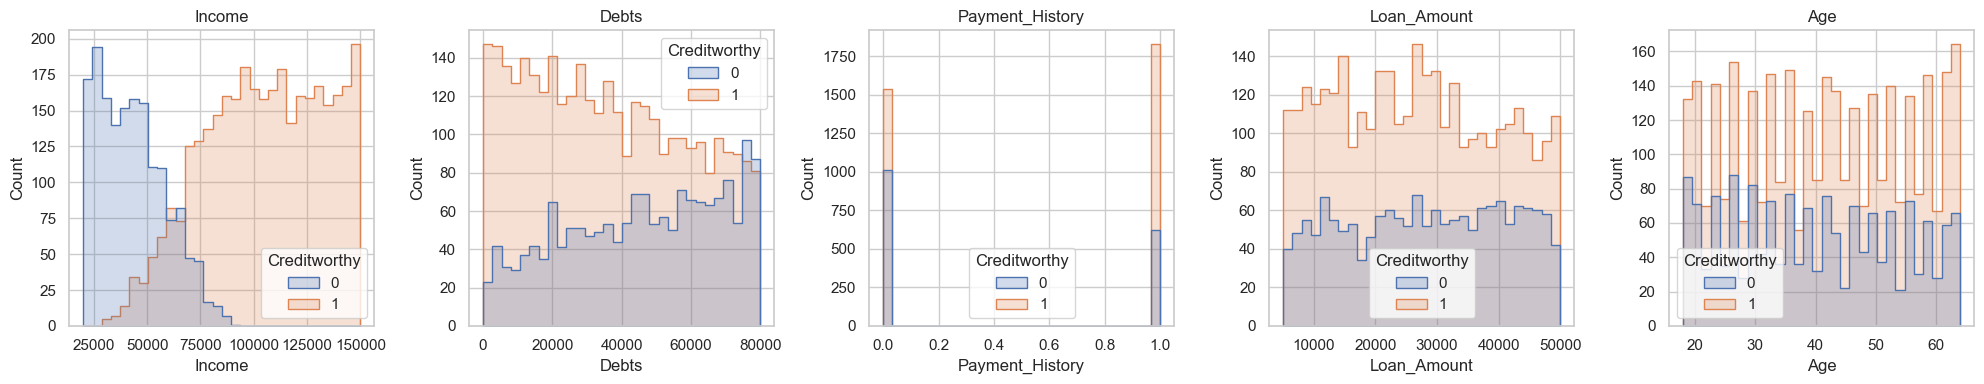

In [5]:
features = df.columns.drop("Creditworthy")
fig, axes = plt.subplots(1, len(features), figsize=(20, 4))
for ax, col in zip(axes, features):
    sns.histplot(data=df, x=col, hue="Creditworthy", bins=30, element="step", ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 2.3 Correlations

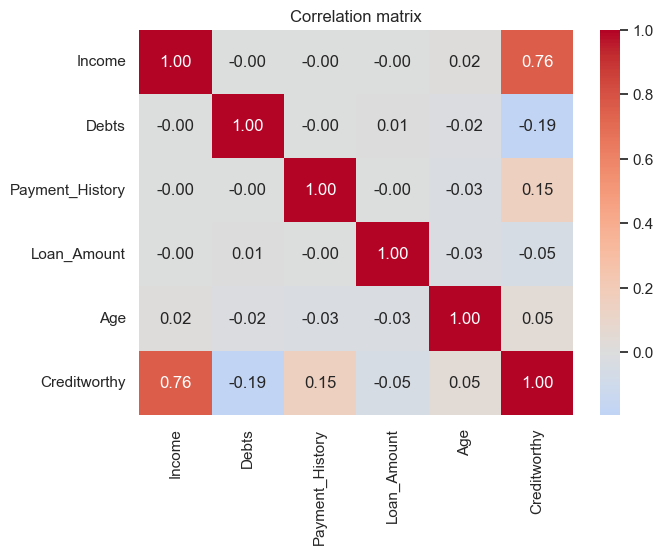

In [6]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

**Observations**
- No missing values or duplicate rows, so no cleaning or imputation is needed. Real credit data would need both.
- **Income** is by far the strongest signal (correlation with the label ≈ 0.76), followed by **Debts** (≈ −0.20) and **Payment_History** (≈ 0.15). Age and Loan_Amount barely separate the classes.
  This matches the labelling formula: Income/1000 has the largest spread of all terms (about 20–150 points).
- The features are independent of each other (correlations ≈ 0) because each one was sampled separately.

## 3. Train / test split
We keep **20 % of the data as a test set** and do not touch it until the final evaluation.
`stratify=y` keeps the class ratio the same in both parts.

In [7]:
X = df.drop(columns="Creditworthy")
y = df["Creditworthy"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (4000, 5)  Test: (1000, 5)


## 4. Baselines and candidate models (5-fold cross-validation)
All models are compared with **stratified 5-fold cross-validation on the training set only**.
Scaling is placed inside a `Pipeline`, so the scaler is fit only on each training fold and no information leaks from the validation fold.

| Model | Why it is included |
|---|---|
| Majority class (`DummyClassifier`) | Lower bound: the score you get without learning anything |
| Logistic Regression | Simple, interpretable linear baseline |
| Decision Tree (unpruned) | The model from the original notebook |
| Decision Tree (depth ≤ 5) | Checks whether a shallower, more interpretable tree is enough |
| Random Forest | Ensemble that usually beats a single tree |

In [8]:
models = {
    "Majority class": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree (unpruned)": DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE),
    "Decision Tree (depth<=5)": DecisionTreeClassifier(criterion="entropy", max_depth=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}
scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "recall_not_creditworthy": make_scorer(recall_score, pos_label=0),
    "f1": "f1",
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({metric: f"{scores['test_' + metric].mean():.3f} ± {scores['test_' + metric].std():.3f}"
                 for metric in scoring} | {"model": name})
cv_results = pd.DataFrame(rows).set_index("model")
cv_results

,accuracy,roc_auc,recall_not_creditworthy,f1
model,,,,
Majority class,0.672 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.804 ± 0.000
Logistic Regression,0.996 ± 0.002,1.000 ± 0.000,0.998 ± 0.003,0.997 ± 0.001
Decision Tree (unpruned),0.975 ± 0.003,0.972 ± 0.003,0.962 ± 0.006,0.981 ± 0.002
Decision Tree (depth<=5),0.961 ± 0.004,0.990 ± 0.002,0.934 ± 0.005,0.971 ± 0.003
Random Forest,0.982 ± 0.003,0.999 ± 0.000,0.972 ± 0.006,0.987 ± 0.002


**Reading the table**
- The majority-class baseline already gets ~0.67 accuracy, but its ROC-AUC is 0.5 and it catches **none** of the risky applicants.
  This is why accuracy alone is not enough.
- **Logistic Regression is close to perfect.** The labelling rule is a *linear* threshold on the features, which is exactly the kind of boundary logistic regression learns.
- The trees have to approximate a diagonal boundary with axis-aligned splits, so they make a few more mistakes near the boundary.

## 5. Hyper-parameter tuning
The original notebook used a decision tree with no limit on its size, which tends to overfit.
Here we tune its depth and minimum leaf size with a grid search, optimising ROC-AUC with the same cross-validation folds.

In [9]:
param_grid = {"max_depth": [3, 5, 7, 10, None], "min_samples_leaf": [1, 5, 20]}
grid = GridSearchCV(DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE),
                    param_grid, cv=cv, scoring="roc_auc")
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_)
print(f"Best CV ROC-AUC: {grid.best_score_:.3f}")

Best params: {'max_depth': 5, 'min_samples_leaf': 20}
Best CV ROC-AUC: 0.992


The search picks a **shallow tree (depth 5, ≥ 20 samples per leaf)**. Its ROC-AUC is higher than the unpruned tree's (≈ 0.99 vs 0.97),
but its accuracy is slightly lower. The unpruned tree makes confident 0/1 predictions, which rank applicants badly, while the
shallow tree gives smoother probabilities. In return, its rules are short enough to explain to a loan officer.

## 6. Final evaluation on the held-out test set
We evaluate two models on the test set:
1. **Logistic Regression**, the best model in cross-validation.
2. The **tuned Decision Tree**, because a tree was the model asked for in the task and its rules are easy to explain.

In [10]:
final_models = {
    "Logistic Regression": models["Logistic Regression"].fit(X_train, y_train),
    "Tuned Decision Tree": grid.best_estimator_,
}
for name, model in final_models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    print(f"===== {name} =====")
    print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.3f}")
    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

===== Logistic Regression =====
ROC-AUC: 1.000
                  precision    recall  f1-score   support

Not creditworthy      0.997     0.997     0.997       328
    Creditworthy      0.999     0.999     0.999       672

        accuracy                          0.998      1000
       macro avg      0.998     0.998     0.998      1000
    weighted avg      0.998     0.998     0.998      1000

===== Tuned Decision Tree =====
ROC-AUC: 0.995
                  precision    recall  f1-score   support

Not creditworthy      0.968     0.936     0.952       328
    Creditworthy      0.969     0.985     0.977       672

        accuracy                          0.969      1000
       macro avg      0.969     0.961     0.965      1000
    weighted avg      0.969     0.969     0.969      1000



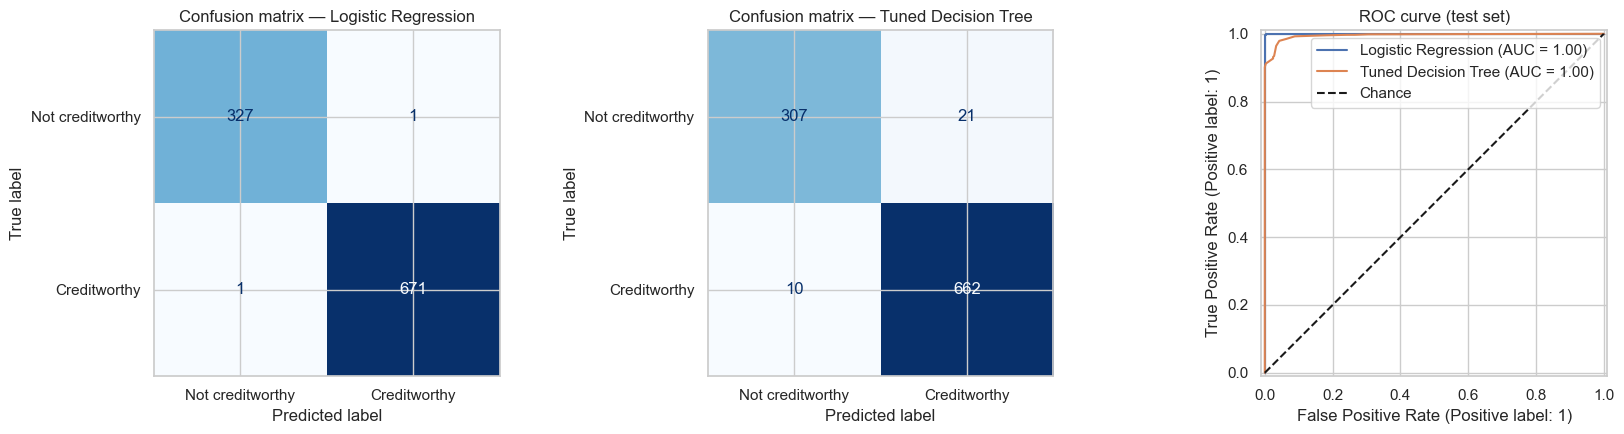

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (name, model) in zip(axes[:2], final_models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, model.predict(X_test)),
                           display_labels=CLASS_NAMES).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Confusion matrix — {name}")
for name, model in final_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=axes[2])
axes[2].plot([0, 1], [0, 1], "k--", label="Chance")
axes[2].legend()
axes[2].set_title("ROC curve (test set)")
plt.tight_layout()
plt.show()

## 7. What did the models learn?
Because we know the true formula, we can check whether the learned importances make sense.

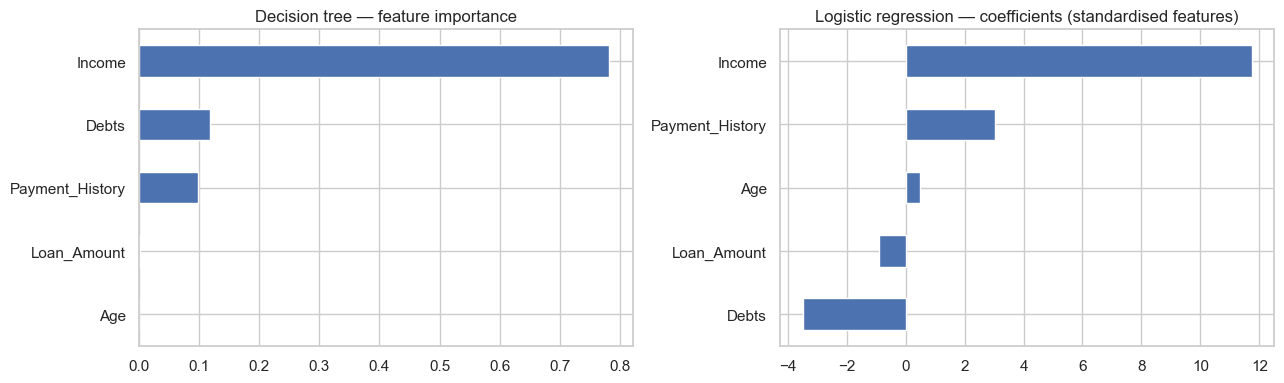

In [12]:
tree = grid.best_estimator_
logreg = final_models["Logistic Regression"][-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pd.Series(tree.feature_importances_, index=features).sort_values().plot.barh(ax=axes[0])
axes[0].set_title("Decision tree — feature importance")
pd.Series(logreg.coef_[0], index=features).sort_values().plot.barh(ax=axes[1])
axes[1].set_title("Logistic regression — coefficients (standardised features)")
plt.tight_layout()
plt.show()

Both models rank **Income** first, followed by **Debts** and **Payment_History**. The logistic-regression signs are also correct:
Debts and Loan_Amount lower creditworthiness, and everything else raises it. So the models recovered the structure of the labelling formula.

## 8. Error analysis
Which applicants does the tuned tree get wrong? Since we know the formula, we can recompute each applicant's hidden `score` and see how far it is from the threshold of 50.

In [13]:
test = X_test.copy()
test["actual"] = y_test
test["predicted"] = tree.predict(X_test)
test["hidden_score"] = (test.Income / 1000 - test.Debts / 2000 + test.Payment_History * 20
                        - test.Loan_Amount / 5000 + test.Age / 10)
errors = test[test.actual != test.predicted]
print(f"{len(errors)} misclassified out of {len(test)}")
print(f"|score - 50| for errors:  median {(errors.hidden_score - 50).abs().median():.1f}")
print(f"|score - 50| for all:     median {(test.hidden_score - 50).abs().median():.1f}")
errors.head(10)

31 misclassified out of 1000
|score - 50| for errors:  median 2.9
|score - 50| for all:     median 35.0


,Income,Debts,Payment_History,Loan_Amount,Age,actual,predicted,hidden_score
408,68354,24729,0,28925,40,1,0,54.2045
2732,55133,44462,1,45363,56,0,1,49.4294
1876,68756,55913,1,6082,42,1,0,63.7831
3531,53160,42982,1,46205,19,0,1,44.3280
3588,68355,77994,1,6473,30,1,0,51.0634
4258,50930,3543,0,31204,21,0,1,45.0177
423,70108,46002,0,33924,43,0,1,44.6222
4150,68563,70246,1,28634,23,1,0,50.0132
1002,77043,51727,0,35215,45,0,1,48.6365
3885,47386,34808,1,7335,44,1,0,52.9150


The misclassified applicants sit **very close to the decision boundary** (score ≈ 50), while a typical applicant is far from it.
The errors come from borderline cases, not from a systematic bias. On real data you would also look for patterns such as
"errors are concentrated in young applicants", which could point to a fairness problem.

## 9. Conclusions and limitations
- On this synthetic data, **Logistic Regression** gives the best and most stable results. This is expected, because the true rule is linear.
- The **majority-class baseline** shows that the ~0.67 accuracy you get for free is meaningless for risk control: it catches 0 % of risky applicants.
- **Limitations:**
  - The labels come from a formula with no noise, so these scores **overstate** what you can expect on real data.
  - There are no missing values, outliers or class-imbalance problems. Real credit data has all three.
  - `Age` is a protected attribute in many lending regulations. A real model would need a fairness review before it could be used.
- **Next steps:** repeat the same pipeline on a real dataset such as German Credit (UCI Statlog), add calibration and threshold tuning based on the cost of a wrong approval, and compare with gradient boosting.